# Importing and initialization

In [42]:
from astropy.stats import sigma_clipped_stats
from astropy.visualization import SqrtStretch
from astropy.visualization.mpl_normalize import ImageNormalize
from astropy.wcs import WCS
from astropy.io import fits
import glob
import os
from scipy.stats import scoreatpercentile
from scipy.optimize import curve_fit
import astropy.units as u
from scipy import stats
from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection
from matplotlib import pyplot as plt
import numpy as np
from matplotlib import colors
from astropy.nddata import CCDData
from ccdproc import wcs_project
from photutils.isophote import EllipseGeometry
from photutils.aperture import EllipticalAperture
from photutils.isophote import Ellipse
from photutils.aperture import ApertureStats
from photutils.aperture import EllipticalAnnulus, EllipticalAperture
#importing needed packages

In [2]:
#Functions TAKEN FROM SURFACE PHOTOMETRY LAB. NOT OUR WORK.
def imdisplay(image, v1perc=10, v2perc=95, logscale=True):
    '''
    display an image 
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    fig,ax = plt.subplots(figsize=(6,6))
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    print(v1,v2)
    if (logscale):
        im = ax.imshow(nimage,cmap='gray_r',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
    else:
        im = ax.imshow(nimage,cmap='gray_r',aspect='equal',vmin=v1,vmax=v2,origin='lower')
        
    cbar = fig.colorbar(im, ax=ax, fraction=0.04)
    cbar.ax.set_ylabel('counts')
    return fig,ax
def imdisplay2(image, v1perc=10, v2perc=95, logscale=True):
    '''
    display two copies of an image side-by-side
    OPTIONAL KEYWORD PARAMETERS
    v1perc: one end of the colormap assigned to the v1perc percent lowest flux 
    v2perc: the other end of the colormap assigned to the v2perc percent highest flux    
    '''
    #this makes two horizontal figures 
    fig,axs = plt.subplots(1,2,figsize=(12,6))
    # make sure image is an np array
    nimage = np.array(image)
    # determine the pixel values at the 10th and 95th percentile
    v1 = scoreatpercentile(nimage,v1perc)
    v2 = scoreatpercentile(nimage,v2perc)
    # display using imshow
    #
    # you can play with alternate cmaps in the function below, such as "viridis" or "gray"
    # The 'gray_r' color map reverses the color-scale so that dark display pixels are the brightest in the image
    #
    # vmin and vmax set the min and max pixel values that
    # will be mapped to the extremes of the colormap
    print(f"v1 = {v1:5.2f}, v2 = {v2:5.2f}")
    if (logscale):
        #plot the two figures side by side
        im0 = axs[0].imshow(nimage,cmap='gray_r',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
        im1 = axs[1].imshow(nimage,cmap='gray_r',aspect='equal',norm=colors.LogNorm(vmin=v1,vmax=v2),origin='lower')
    else:
        im0 = axs[0].imshow(nimage,cmap='gray_r',aspect='equal',vmin=v1,vmax=v2,origin='lower')
        im1 = axs[1].imshow(nimage,cmap='gray_r',aspect='equal',vmin=v1,vmax=v2,origin='lower')

    #plot colorbars for each subplot
    cbar0 = fig.colorbar(im0, ax=axs[0], fraction=0.04)
    cbar0.ax.set_ylabel('counts')
    cbar1 = fig.colorbar(im1, ax=axs[1], fraction=0.04)
    cbar1.ax.set_ylabel('counts')
    return fig,axs

def background_meas(imname,data,header,fig,ax,corners,bkg_size=5):
    #need to find ways to select regions of pixels in image
    fig,ax = imdisplay(data,v1perc=1,v2perc=99,logscale=True)

    plt.title(imname)

    #print out the x and y-dimension of the image using the header keywords
    print('image xdim = ', header['NAXIS1'], '; image ydim = ',header['NAXIS2'])
    #the length of each background box size
    #bkg_size = 200

    #make an array whose elements are the different data sections.
    reg = np.array([])


    #specify the different regions.  Each will be appended to the reg array.  the reg array is therefore 3 dimensional.  
    #the first dimension is for each region.  Each of those dimensions contains a 2D array that holds the image section.
    reg = np.append(reg, data[corners[0][0]:bkg_size-1, corners[0][1]:bkg_size-1])    #lower left corner
    reg = np.append(reg, data[corners[1][0]:bkg_size-1, corners[1][1]:])    #upper left corner
    reg = np.append(reg, data[corners[2][0]:, corners[2][1]:])    #upper right corner
    reg = np.append(reg, data[corners[3][0]:, corners[3][1]:bkg_size-1])   #lower right corner

    #print the median and mode of all the pixels. 
    bkgmode =stats.mode(reg,keepdims=False)[0]
    bkgmed = np.median(reg)
    print('mode = ',bkgmode)
    print('median = ',bkgmed)

    #Overlay rectangles with the background region indicated
    rectlist = []
    #loop through all images 
    for corn in corners:
        rect = plt.Rectangle((corn),bkg_size, bkg_size,linewidth=2,angle=0.0)
        rectlist.append(rect)
        pc = PatchCollection(rectlist,linewidth=1,edgecolor='r',facecolor='none')
        ax.add_collection(pc)
        
    return bkgmode,bkgmed
def bkgregplot(data,header,imname, bkgdim, fig, ax):
    #define lower-left corners of each region
    corners = []
    corners.append([0,0])
    corners.append([0,header['NAXIS2']-bkgdim])
    corners.append([header['NAXIS1']-bkgdim, header['NAXIS2']-bkgdim])
    corners.append([header['NAXIS1']-bkgdim,0])

    #run the background_meas code to measure the background and plot the background regions
    bkgmode,bkgmed = background_meas(imname, data, header, fig, ax, 
                                                       corners,bkg_size=bkgdim)
    return bkgmode, bkgmed
#this subroutine will plot every other isophote on top of the galaxy image
def plotaper(galname, image, isophote_list,vminperc=40,vmaxperc=99.99):

    #plot image
    #plt.subplots(figsize=(6,6))
    fig,ax = imdisplay2(image,v1perc=vminperc,v2perc=vmaxperc,logscale=True)

    #Loop through all apertures starting at the first (not zero) and going to every other aperture
    for i in range(1, len(isophote_list.sma),2):
        #create an elliptical aperture with the the correct geometry.  
        #Task is described here https://photutils.readthedocs.io/en/stable/api/photutils.aperture.EllipticalAperture.html#photutils.aperture.EllipticalAperture
        aperiter = EllipticalAperture((isophote_list.x0[i], isophote_list.y0[i]), isophote_list.sma[i], 
                                      isophote_list.sma[i] * (1-isophote_list.eps[i]), isophote_list.pa[i])
    
        #overplot apertures
        aperiter.plot(ax=ax[0],color='red')

    #plot the isophotes that have parameters fixed to the median parameters of all but the "apmin" inner isphotes
    #compute median isophote parameters ignoring inner isophotes.  This is because the inner isophotes all tend to be rather circular
    apmin = 20   #the minimum inner isophote in terms of isophote number.
    xcenav = np.median(isophote_list.x0[apmin:])
    ycenav = np.median(isophote_list.y0[apmin:])
    epsav = np.median(isophote_list.eps[apmin:])
    paav = np.median(isophote_list.pa[apmin:])
    
    #fig,ax = imdisplay(image,v1perc=vminperc,v2perc=vmaxperc,logscale=True)
    for i in range(1, len(isophote_list.sma),2):
        #create an elliptical aperture with the the correct geometry.  
        #Task is described here https://photutils.readthedocs.io/en/stable/api/photutils.aperture.EllipticalAperture.html#photutils.aperture.EllipticalAperture
        aperiter = EllipticalAperture((xcenav, ycenav), isophote_list.sma[i], 
                                      isophote_list.sma[i] * (1-epsav), paav)
    
        #overplot apertures
        aperiter.plot(ax=ax[1],color='blue')

    ax[0].set_title(galname + ' free ellipse parameters')
    ax[1].set_title(galname + ' fixed ellipse parameters')

    return xcenav, ycenav, epsav, paav
def plotellipse(isolist):
    plt.figure(figsize=(8, 8))
    plt.subplots_adjust(hspace=0.35, wspace=0.35)

    #plot the semi-major axis vs. the ellipticity
    plt.subplot(2, 2, 1)
    plt.errorbar(isolist.sma, isolist.eps, yerr=isolist.ellip_err,
                 fmt='o', markersize=4)
    plt.xlabel('Semimajor Axis Length (pix)')
    plt.ylabel('Ellipticity')

    #plot the semi-major axis vs. the PA
    plt.subplot(2, 2, 2)
    plt.errorbar(isolist.sma, isolist.pa / np.pi * 180.0,
                 yerr=isolist.pa_err / np.pi * 80.0, fmt='o', markersize=4)
    plt.xlabel('Semimajor Axis Length (pix)')
    plt.ylabel('PA (deg)')

    #plot the semi-major axis vs. the x center of that ellipse
    plt.subplot(2, 2, 3)
    plt.errorbar(isolist.sma, isolist.x0, yerr=isolist.x0_err, fmt='o',
                 markersize=4)
    plt.xlabel('Semimajor Axis Length (pix)')
    plt.ylabel('x0')

    #plot the semi-major axis vs. the y center of that ellipse
    plt.subplot(2, 2, 4)
    plt.errorbar(isolist.sma, isolist.y0, yerr=isolist.y0_err, fmt='o',
                 markersize=4)
    plt.xlabel('Semimajor Axis Length (pix)')
    plt.ylabel('y0')

In [3]:
#initialize dictionaries
imname = {} #list of galaxy images
imname_sub = {} #list of background-subtracted images
data = {} #all data
datag = {} #g band data
datar = {} #r band data
dataz = {} #z band data
header = {} #headers
initparams = {} #initial ellipse parameters
geometry = {} #stores ellipse geometry
ellipse = {}
isolist = {}
xcenav = {}
ycenav = {}
epsav = {}
paav = {}
rhalfasec = {}
rcent = {}
sbcent = {}
sbcent_err = {}
totflux = {}
totflux_err = {}

#unused dictionaries
#datag_sub = {} #background subtracted g band data
#datar_sub = {} #background subtracted r band data
#dataz_sub = {} #background subtracted z band data
#corners = {} #used in location of background areas
#kgdim = {} #size of background measurement
#bkgmodeg = {} #mode of g background
#bkgmoder = {} #mode of r background
#bkgmodez = {} #mode of z background
#bkgmedg = {} #median of g background
#bkgmedr = {} #median of r background
#bkgmedz = {} #median of z background

# Import and set up galaxy images

In [4]:
datadir = '/home/c690j196/ASTR596/Capstone/Data'
os.chdir(datadir)
#set data directory

In [24]:
#import and label all galaxy images\
imname['NGC2528'] = 'cutout_121.8537_39.1945.fits'
imname['NGC2532'] = 'cutout_122.5600_33.9567.fits'
imname['NGC6119'] = 'cutout_244.9256_37.8063.fits'

In [25]:
#extract all images as arrays
for galname in imname:
    data[galname],header[galname] = fits.getdata(imname[galname], header=True) #extract data and header
    #now separate data by band
    datag[galname] = data[galname][0]
    datar[galname] = data[galname][1]
    dataz[galname] = data[galname][2]

In [26]:
#was unsure if images were background subtracted, so performed a background subtraction as per the lesson to see if the images improved or deteriorated. They deteriorated, so I commented out the relevant code.
#for galname in imname:
    #bkgmodeg[galname],bkgmedg[galname] = bkgregplot(datag[galname],header[galname],imname[galname], bkgdim[galname], fig, ax)
    #bkgmoder[galname],bkgmedr[galname] = bkgregplot(datar[galname],header[galname],imname[galname], bkgdim[galname], fig, ax)
    #bkgmodez[galname],bkgmedz[galname] = bkgregplot(dataz[galname],header[galname],imname[galname], bkgdim[galname], fig, ax)

In [27]:
#for galname in imname: #for each galaxy
    #subtract the background in each band
    #datag_sub[galname] = datag[galname] - bkgmedg[galname]
    #datar_sub[galname] = datar[galname] - bkgmedr[galname]
    #dataz_sub[galname] = dataz[galname] - bkgmedz[galname]

# Find initial parameters (via ds9)

## NGC 2528 initial parameters:

In [28]:
initparams['NGC2528']={}
initparams['NGC2528']['xcen']= 132
initparams['NGC2528']['ycen']= 127
initparams['NGC2528']['sma']= 81
initparams['NGC2528']['smina']=47
initparams['NGC2528']['PA']= 0

## NGC 2532 initial parameters

In [29]:
initparams['NGC2532']={}
initparams['NGC2532']['xcen']= 92
initparams['NGC2532']['ycen']= 133
initparams['NGC2532']['sma']= 59
initparams['NGC2532']['smina']= 40
initparams['NGC2532']['PA']= 20

## NGC 6119 initial parameters

In [30]:
initparams['NGC6119']={}
initparams['NGC6119']['xcen']= 139
initparams['NGC6119']['ycen']= 125
initparams['NGC6119']['sma']= 68
initparams['NGC6119']['smina']= 46
initparams['NGC6119']['PA']= 160

# Identify apertures

## Get ellipse geometry:

0.05238936468958855 3.609174287557133
0.0018334200140088797 7.0109661245334305
0.027894152328372 1.3178313382863722


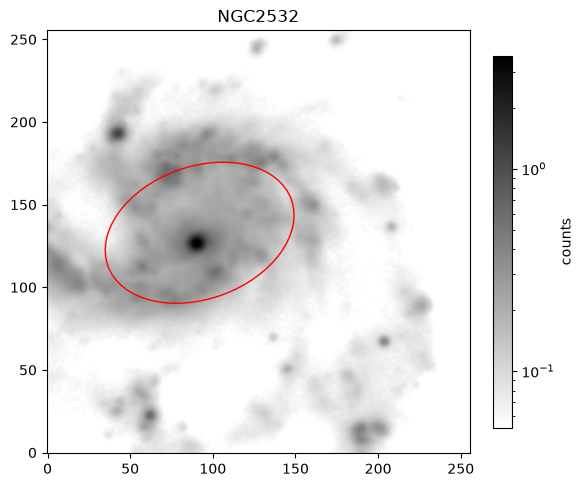

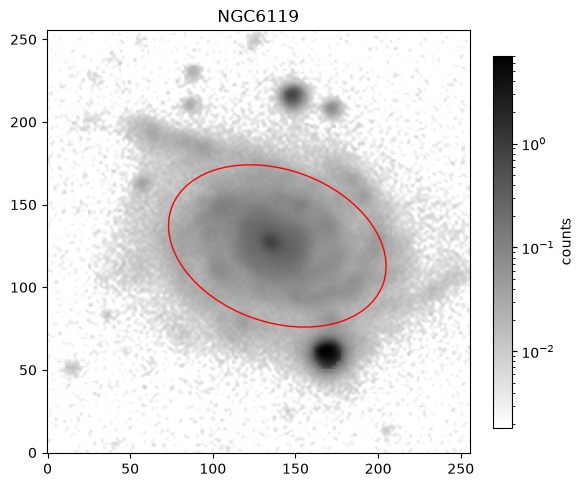

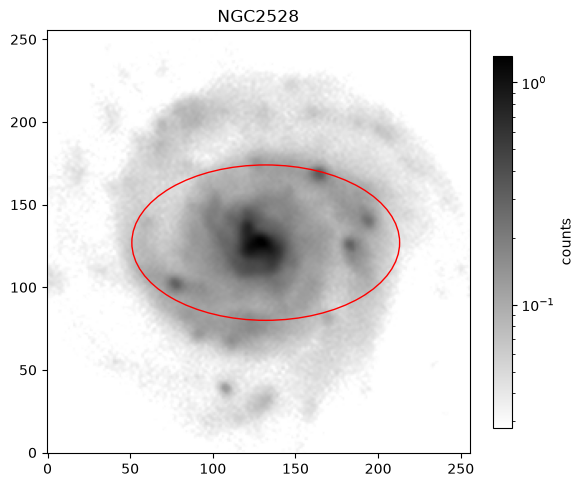

In [31]:
for galname in imname:
    initparams[galname]['ellip'] = 1. - initparams[galname]['smina'] / initparams[galname]['sma']
    geometry[galname] = EllipseGeometry(x0 = initparams[galname]['xcen'], 
                                      y0 = initparams[galname]['ycen'],
                                      sma = initparams[galname]['sma'],
                                      eps = initparams[galname]['ellip'],
                                      pa = initparams[galname]['PA'] * np.pi/180)   #convert into radians

    aper = EllipticalAperture((geometry[galname].x0, geometry[galname].y0), geometry[galname].sma, 
                          geometry[galname].sma * (1.-geometry[galname].eps), geometry[galname].pa)#plot our image
    #fig,ax = plt.subplots(figsize=(6,6))
    fig,ax = imdisplay(datag[galname],v1perc=40,v2perc=99.99,logscale=True)
    aper.plot(color='red')
    plt.title(galname)

## Get aperture geometry:

v1 =  0.05, v2 =  3.61
v1 =  0.00, v2 =  7.01
v1 =  0.03, v2 =  1.32


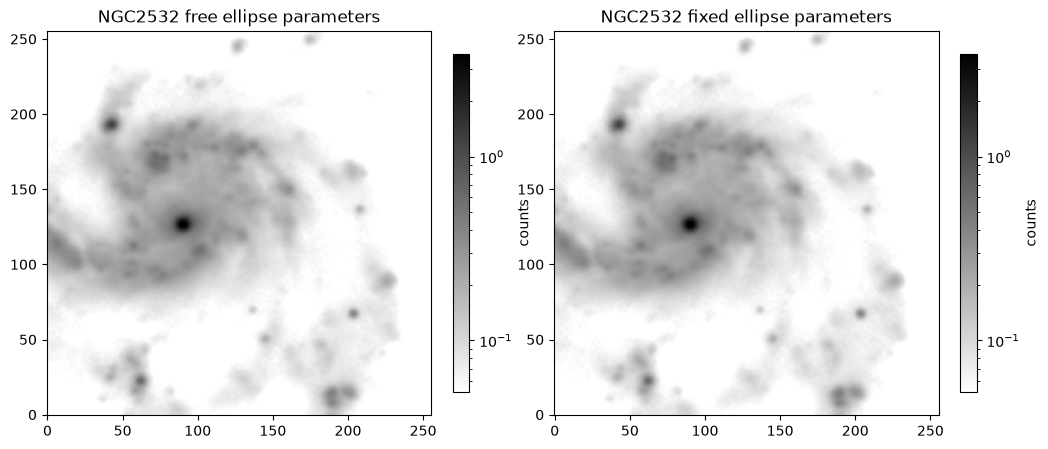

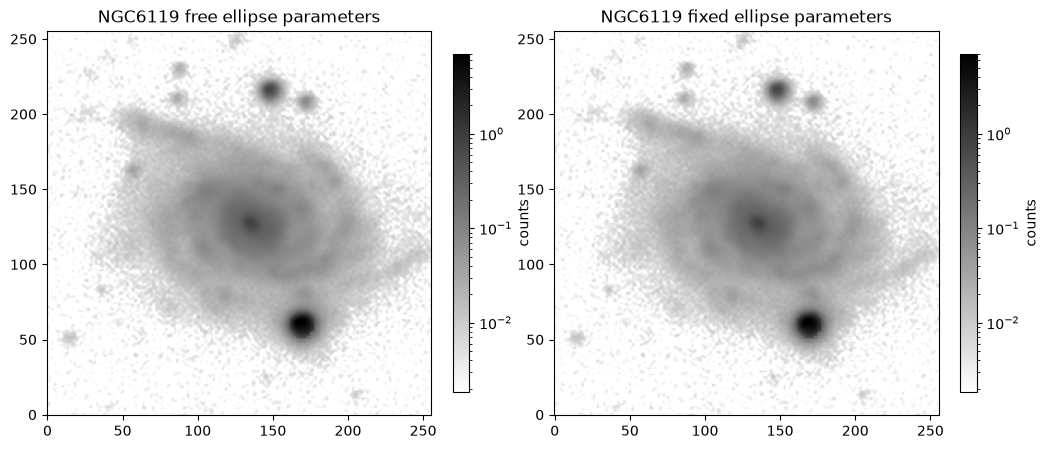

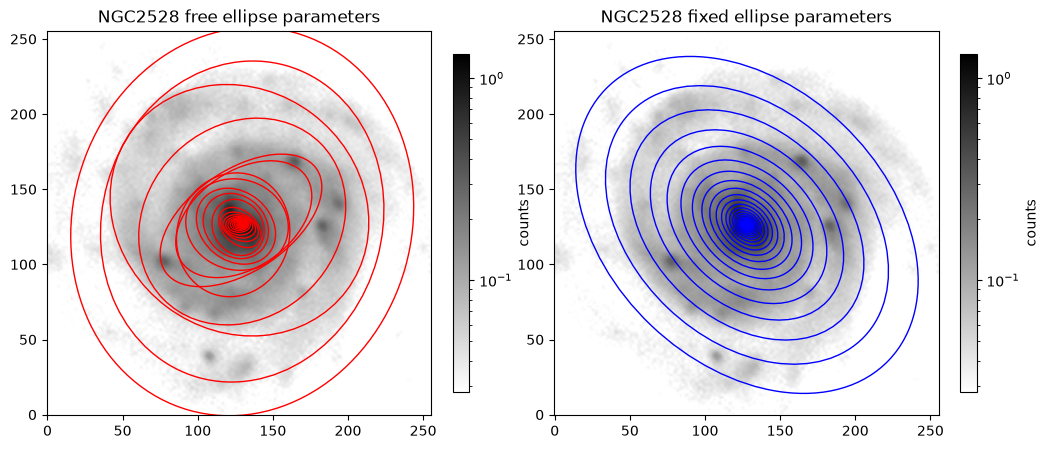

In [32]:
for galname in imname:
    ellipse[galname] = Ellipse(datag[galname], geometry[galname])
    isolist[galname] = ellipse[galname].fit_image()
    xcenav[galname], ycenav[galname], epsav[galname], paav[galname] = plotaper(galname, datag[galname],isolist[galname])

# Find central surface brightness

## Get surface brightness distribution:

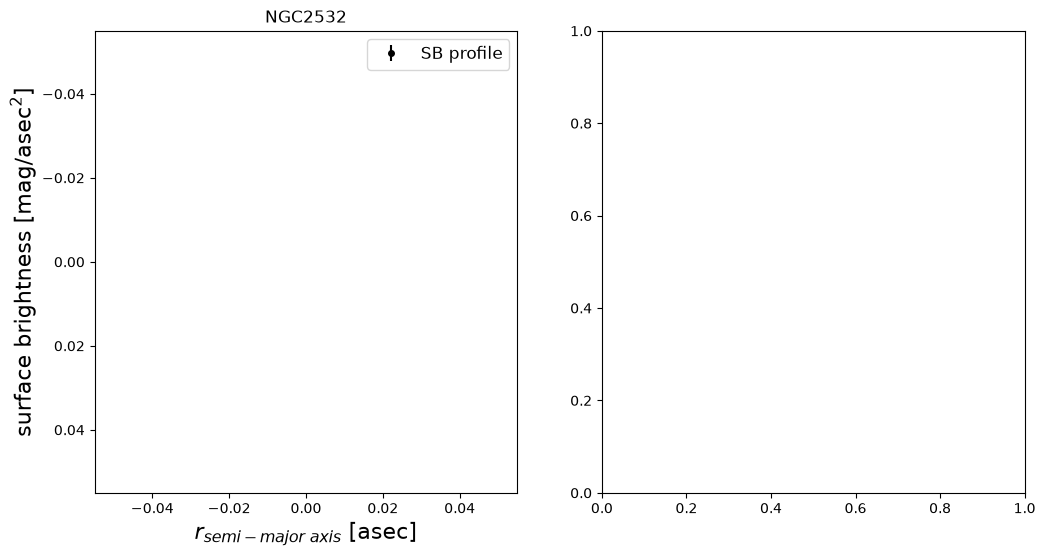

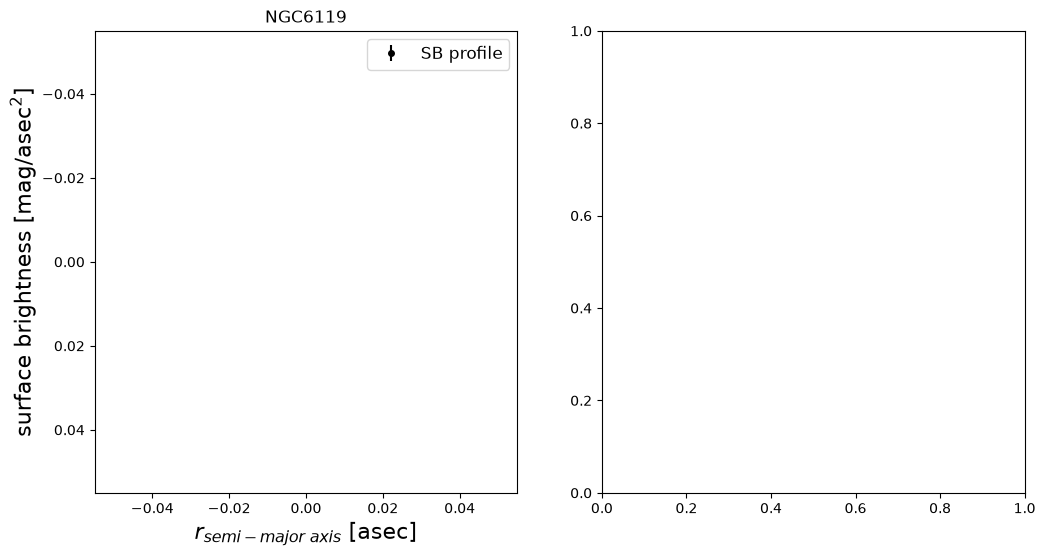

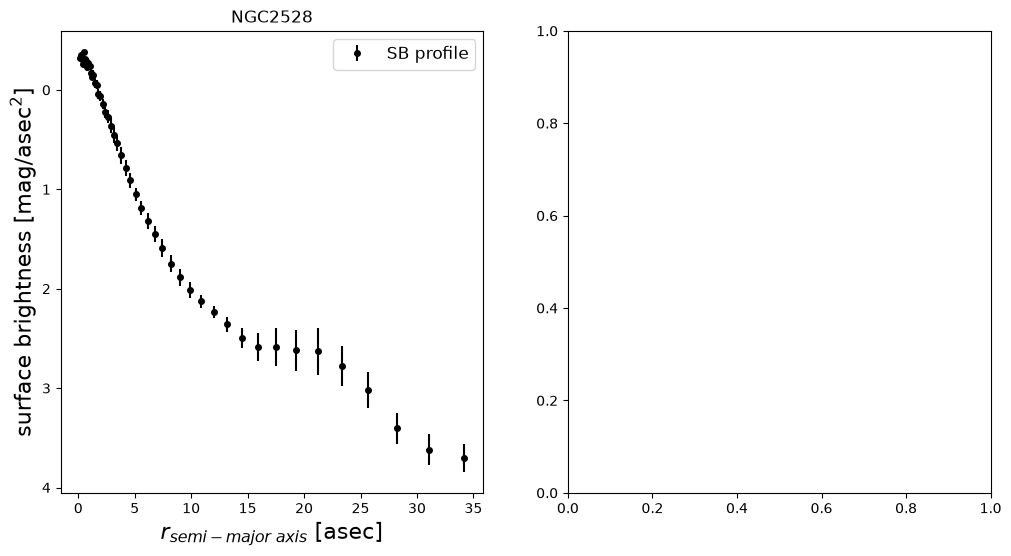

In [52]:
for galname in imname:
    pixscale = header[galname]['CD2_2'] * 3600
    rcent[galname] = np.array([])
    sbcent[galname] = np.array([])
    sbcent_err[galname] = np.array([])
    totflux[galname] = np.array([])
    totflux_err[galname] = np.array([])
    for aindx, a_out in enumerate(isolist[galname].sma):
        #skip the first isophote because I will always compute the values between the current isophote and the previous
        if aindx==0:
            a_in = 0.01
        if aindx>0:
            #create the inner and outer minor axes from the major axes and ellipticity
            b_out = a_out * (1.-epsav[galname])
            b_in = a_in * (1.-epsav[galname])
            #print(f'a_out = {a_out:.2f}; a_in ={a_in:.2f}; b_out ={b_out:.2f}; b_in ={b_in:.2f}')
            #set up elliptical annulus using parameters at rhalf
            annulus_aperture = EllipticalAnnulus((xcenav[galname],ycenav[galname]), 
                                             a_in, a_out, b_out, b_in = b_in,
                                             theta = paav[galname])
            total_aperture = EllipticalAperture((xcenav[galname],ycenav[galname]), 
                                             a_out, b_out, theta = paav[galname])
            aperstats_ann = ApertureStats(datag[galname],annulus_aperture)
            #aperstats_tot = ApertureStats(datag[galname],total_aperture)
            a_in = a_out
            #the central radius of each annulus in asec.  I'm appending each central radius to the existing array
            rcent[galname] = np.append(rcent[galname], (a_in + a_out) / 2.*pixscale)
            #the average pixel flux within each annulus
            avflux = aperstats_ann.mean
            #the standard deviation of the pixel values within each annulus
            stdflux = aperstats_ann.std
            #the number of pixels in each annulus
            numpix = aperstats_ann.sum_aper_area
            #Now do the total within each aperture
            #totflux[galname] = np.append(totflux[galname],aperstats_tot.sum)
            #totflux_err[galname]= np.append(totflux_err[galname],aperstats_tot.std)
        
            #****************************
            #your code here
            #the area of a pixel
            pixarea = pixscale*4
            #determine the average surface brightness in mag/asec^2.
            sbcent[galname] = np.append(sbcent[galname], -2.5*np.log10(avflux*pixarea))
            # the uncertainty in the mean flux (this is not the standard deviation of all the pixels in the aperture).  
            # Check back to Homework 1
            #avflux_err = a
            #avflux_err = avflux_err * u.pix   #this gets rid of the units on the flux error so that the next part works
            sbcent_err[galname] = np.append(sbcent_err[galname], stdflux/(avflux*np.log(10))) #pixel area factor cancels out
            
    fig,ax = plt.subplots(1,2,figsize=(12, 6))
    #plot the semi-major axis vs. magnitude
    ax[0].errorbar(rcent[galname], sbcent[galname], yerr=sbcent_err[galname], 
             fmt='o', markersize=4, color='black', label='SB profile')
    ax[0].invert_yaxis()
    ax[0].legend(fontsize=12)
    ax[0].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
    ax[0].set_ylabel('surface brightness [mag/asec$^2$]',fontsize=16)
    ax[0].set_title(galname)
    scipy.optimize.curve_fit(ax+b, rcent[galname], sbcent[galname])


# Fit Surface Brightness Curves:

In [ ]:
#plot the curve of growth
ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
             fmt='o', markersize=4, color='black', label='curve of growth')
ax[0].errorbar(rcent, totflux, yerr=totflux_err, 
             fmt='-', markersize=4, color='magenta', label='curve of growth')

#ax[0].axvline(rhalfasec[galname], color='red', label='$r_{half}$')
ax[0].legend(fontsize=12)

ax[0].set_xlabel('$r_{semi-major~axis}$ [asec]',fontsize=16)
ax[0].set_ylabel('enclosed flux within ellipse',fontsize=16)
ax[0].set_title(galname)

#measure the half-light radius
#a horizontal line at half the total flux
ax[0].axhline(totflux[-1]/2., color='red')

#a vertical line at half the total flux
#*************************
#You will need to adjust rhalfpix by eye to get the radius that encompasses half the light.
#you shoul do this using the plot you make, not using the image itself.
rhalfasec[galname] = 
ax[0].axvline(rhalfasec[galname], color='red')
print(f'the half-light radius = {rhalfasec[galname]:.3f} [asec]')

#plot the same line on the surface brightness plot
ax[1].axvline(rhalfasec[galname], color='red', label='$r_{half}$')

#calculate and print the surface brightness somewhere within 3 arcsec from the center.  
#Note that some of the inner values have NaNs because the isophote fitting failed there.  
#Just keep going out in index until you get a valid value
#***********************
#your code here
print('your answer')

#calculate and print out the surface brightness at the effective radius
#***********************
#your code here
#find the isophote that best corresponds to the half-light radius
#We will do this by computing the difference between the half-light radius
#and the semi-major axis of each isophote.  
diff = rcent - rhalfasec[galname]

#this returns the index of the isophote that is closes to the half-light radius
#We use this to set the ellipticity and PA of the isophotes
rhalfasecind = np.argmin(abs(diff))


print('your answer')

#calculate and print out the ratio of the **flux** surface brightness between the center and at r_half
#***********************
#your code here
flux_rat = 
print(f'flux_SB(rhalf) / flux_SB(rcent) = {flux_rat:.3f}')

In [51]:
print(header['NGC2528'])

SIMPLE  =                    T / file does conform to FITS standard             BITPIX  =                  -32 / number of bits per data pixel                  NAXIS   =                    3 / number of data axes                            NAXIS1  =                  256 / length of data axis 1                          NAXIS2  =                  256 / length of data axis 2                          NAXIS3  =                    3 / length of data axis 3                          EXTEND  =                    T / FITS dataset may contain extensions            COMMENT   FITS (Flexible Image Transport System) format is defined in 'AstronomyCOMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H SURVEY  = 'DECaLS  '                                                            VERSION = 'DR11-north'                                                          IMAGETYP= 'IMAGE   '           / None                                           BANDS   = 'grz     '                    